# Персональные top-10 рекомендации ресторанов: Yelp Academic Dataset


## 1. Источник и загрузка данных

- **Оригинальный источник:** [Yelp Open Dataset](https://business.yelp.com/data/resources/open-dataset/).
- **Страница скачивания:** [Yelp Dataset на Kaggle](https://www.kaggle.com/datasets/yelp-dataset/yelp-dataset/data?select=yelp_academic_dataset_user.json) (зафиксировать скачанную версию, например v4).
- **Файлы:** 

    `yelp_academic_dataset_review.json` (ID пользователя/заведения, оценка, дата); 

    `yelp_academic_dataset_business.json` (категории, город, свойства); 

    `yelp_academic_dataset_user.json` (профиль пользователя, дата регистрации).


- **Способ получения:** скачать указанные файлы со страницы датасета, поместить в папку `data/raw/`.


**Поля взаимодействий:** `user_id` — пользователь; `business_id` — заведение; `stars` — явная оценка 1–5; `date` — момент написания отзыва.

In [208]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
RAW = Path("data")
DATASET_VERSION = 4
BUSINESS = RAW / "yelp_academic_dataset_business.json"
REVIEW = RAW / "yelp_academic_dataset_review.json"
USER = RAW / "yelp_academic_dataset_user.json"

for path in (BUSINESS, REVIEW, USER):
    if not path.is_file():
        raise FileNotFoundError(f"Положите файл в {path} или измените RAW")

print(f"Версия датасета: {DATASET_VERSION}")


Версия датасета: 4


In [209]:

import warnings

warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning,
    message=".*encountered in matmul"
)

### 1.1. Воспроизводимая подвыборка
Так как исходный датасет достаточно большой Исходных заведений: 150346, Исходных отзывов: 6990280, для работы я использую только его часть.

Сначала оставляю рестораны города Philadelphia. Затем выбираю 20% пользователей с помощью хэш функции по user_id. Этот способ позволяет при каждом запуске кода получать одну и ту же выборку. Для отобранных пользователей сохраняю все их отзывы о ресторанах города Philadelphia.

После отбора проверяю, сколько осталось пользователей, ресторанов и оценок. 

In [210]:
SAMPLE_MOD = 5  #1/5 пользователей
CITY = "philadelphia"

def keep_user(uid: str) -> bool:
    digest = hashlib.sha256(uid.encode("utf-8")).digest()
    return int.from_bytes(digest[:8], "big") % SAMPLE_MOD == 0

restaurants = {}
raw_business_count = 0
with BUSINESS.open(encoding="utf-8") as f:
    for line in f:
        b = json.loads(line)
        raw_business_count += 1
        categories = {c.strip() for c in (b.get("categories") or "").split(",")}
        if (b.get("city") or "").strip().casefold() == CITY and "Restaurants" in categories:
            restaurants[b["business_id"]] = {
                "name": b.get("name"), "categories": b.get("categories"),
                "attributes": b.get("attributes"), "city": b.get("city")
            }

rows = []
raw_review_count = 0
with REVIEW.open(encoding="utf-8") as f:
    for line in f:
        r = json.loads(line)
        raw_review_count += 1
        if r["business_id"] in restaurants and keep_user(r["user_id"]):
            rows.append((r["user_id"], r["business_id"], r.get("stars"), r.get("date"), r.get("review_id")))

interactions = pd.DataFrame(rows, columns=["user_id", "business_id", "stars", "date", "review_id"])
meta_business = pd.DataFrame.from_dict(restaurants, orient="index").rename_axis("business_id").reset_index()

stats = pd.DataFrame({
    "Показатель": [
        "Пользователи",
        "Рестораны",
        "Взаимодействия"
    ],
    "Количество": [
        interactions["user_id"].nunique(),
        interactions["business_id"].nunique(),
        len(interactions)
    ]
})

display(stats)

interactions.head()

,Показатель,Количество
0,Пользователи,42316
1,Рестораны,5557
2,Взаимодействия,137034


,user_id,business_id,stars,date,review_id
0,eUta8W_HdHMXPzLBBZhL1A,04UD14gamNjLY0IDYVhHJg,1.0,2015-09-23 23:10:31,JrIxlS1TzJ-iCu79ul40cQ
1,Dd1jQj7S-BFGqRbApFzCFw,YtSqYv1Q_pOltsVPSx54SA,5.0,2013-06-24 11:21:25,oyaMhzBSwfGgemSGuZCdwQ
2,IQsF3Rc6IgCzjVV9DE8KXg,eFvzHawVJofxSnD7TgbZtg,5.0,2014-11-12 15:30:27,Xs8Z8lmKkosqW5mw_sVAoA
3,mNITUu6B2wUKBOa4NmUHJg,NQSnr4RPUScss607oxOaqw,5.0,2016-05-19 06:10:14,mCVyppNwK2qPOJHXgs0p2Q
4,OkjeFppodgJP_CvB84cJYw,FHNIvNgh3fS7VZQq2Y3dsA,3.0,2014-07-13 18:28:58,8GZbCEMxrbqmRinDbfHWVQ


### 1.2. Метаданные пользователей

Из файла `yelp_academic_dataset_user.json` загружаем информацию только о пользователях, которые попали в нашу выборку. Всего получилось 42 316 профилей.

Пока используем только user_id и yelping_since (дату регистрации пользователя).

В файле также есть количество отзывов, средняя оценка пользователя, число друзей и другие характеристики. Но эти значения могли измениться со временем и включать информацию из будущего, поэтому пока не будем использовать их в моделях, чтобы избежать утечки данных.

In [211]:
chosen_users = set(interactions["user_id"])
user_rows = []
with USER.open(encoding="utf-8") as f:
    for line in f:
        x = json.loads(line)
        if x["user_id"] in chosen_users:
            user_rows.append({"user_id":x["user_id"], "yelping_since":x.get("yelping_since")})
meta_users = pd.DataFrame(user_rows, columns=["user_id", "yelping_since"])
meta_users.head()

,user_id,yelping_since
0,qVc8ODYU5SZjKXVBgXdI7w,2007-01-25 16:47:26
1,NIhcRW6DWvk1JQhDhXwgOQ,2005-12-30 13:47:19
2,qsHZ6_yT870pmm4Oxvw5Og,2011-06-16 01:55:54
3,n8bbgZJLENE4dC4E743ukQ,2010-12-17 19:29:57
4,OJorsQjotS1dIv--IVifCA,2011-09-25 19:36:00


## 2. EDA: анализ данных

Проверим пропуски и дубликаты, посмотрим на распределение оценок, активность пользователей и популярность ресторанов. Также оценим разреженность данных и доступные метапризнаки для дальнейшего обучения моделей.

In [212]:
print("Размер:", interactions.shape)
print("Пропуски:\n", interactions.isna().sum().to_string())
print("Дубликаты строк:", interactions.duplicated().sum())
print("Повторяющиеся пары user-business:", interactions.duplicated(["user_id", "business_id"]).sum())
print("Значения stars:\n", interactions["stars"].value_counts(dropna=False).sort_index())
print("Пропуски в категориях ресторанов:", meta_business.categories.isna().sum())

Размер: (137034, 5)
Пропуски:
 user_id        0
business_id    0
stars          0
date           0
review_id      0
Дубликаты строк: 0
Повторяющиеся пары user-business: 4349
Значения stars:
 stars
1.0    13284
2.0    11409
3.0    18116
4.0    38828
5.0    55397
Name: count, dtype: int64
Пропуски в категориях ресторанов: 0


Диапазон дат: 2005-02-16 04:06:26 — 2022-01-19 19:26:37
Недопустимые оценки: 0


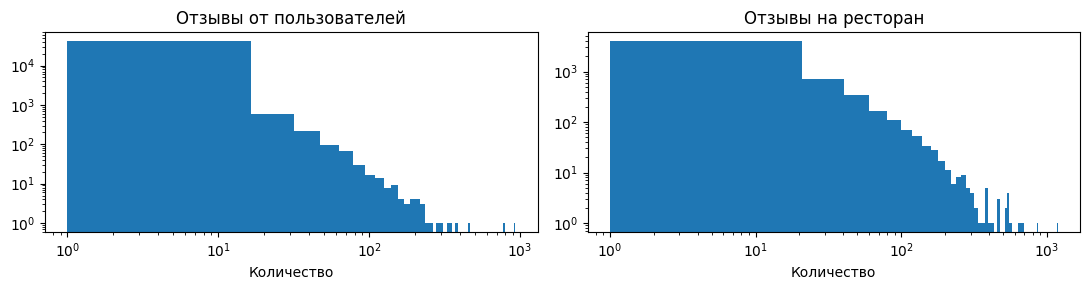

Users: 42316, items: 5557, pairs: 132685, density: 0.0564%, sparsity: 99.9436%
Квантили активности пользователей (отзывы):
 0.00      1.0
0.25      1.0
0.50      1.0
0.75      2.0
0.90      6.0
0.99     34.0
1.00    929.0
dtype: float64
Квантили популярности ресторанов (отзывы):
 0.00       1.00
0.25       3.00
0.50       9.00
0.75      25.00
0.90      60.00
0.99     222.32
1.00    1185.00
dtype: float64
Матрица: 42,316 × 5,557; известных пар: 132,685; Заполненность коллаборативной матрицы = 0.056%


In [213]:
interactions["date"] = pd.to_datetime(interactions["date"], errors="coerce")
interactions["stars"] = pd.to_numeric(interactions["stars"], errors="coerce")
print("Диапазон дат:", interactions.date.min(), "—", interactions.date.max())
print("Недопустимые оценки:", (~interactions.stars.between(1,5)).sum())

activity = interactions.groupby("user_id").size()
popularity = interactions.groupby("business_id").size()
fig, axes = plt.subplots(1,2,figsize=(11,3))
axes[0].hist(activity, bins=60); axes[0].set(xscale="log", yscale="log", title="Отзывы от пользователей", xlabel="Количество")
axes[1].hist(popularity, bins=60); axes[1].set(xscale="log", yscale="log", title="Отзывы на ресторан", xlabel="Количество")
plt.tight_layout(); plt.show()

n_users = interactions.user_id.nunique()
n_items = interactions.business_id.nunique()
n_pairs = interactions[["user_id","business_id"]].drop_duplicates().shape[0]
density = n_pairs / (n_users * n_items) if n_users*n_items else np.nan
print(f"Users: {n_users}, items: {n_items}, pairs: {n_pairs}, density: {density:.4%}, sparsity: {1-density:.4%}")
print("Квантили активности пользователей (отзывы):\n", activity.quantile([0,.25,.5,.75,.9,.99,1]))
print("Квантили популярности ресторанов (отзывы):\n", popularity.quantile([0,.25,.5,.75,.9,.99,1]))

n_observed = interactions[["user_id", "business_id"]].drop_duplicates().shape[0]
density = n_observed / (n_users * n_items) if n_users and n_items else np.nan
print(f"Матрица: {n_users:,} × {n_items:,}; известных пар: {n_observed:,}; "
      f"Заполненность коллаборативной матрицы = {density:.3%}")

#### Видим, что у большинства пользователей очень мало отзывов и большинство ресторанов получают относительно мало отзывов, а небольшая часть очень много.

### 2.1. Распределение оценок и отзывов

Посмотрим, какие оценки пользователи ставят чаще всего и как менялось количество отзывов со временем. Также посчитаем, какую долю составляют положительные оценки (4–5 звёзд).

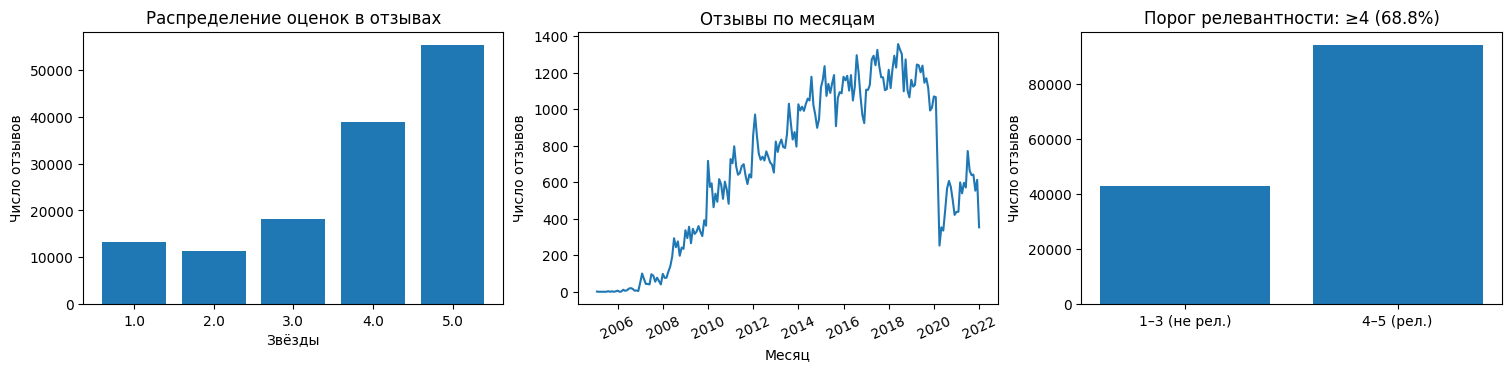

Положительных оценок (4–5): 94,225 из 137,034


In [214]:
eda = interactions.copy()
eda["stars"] = pd.to_numeric(eda["stars"], errors="coerce")
eda["date"] = pd.to_datetime(eda["date"], errors="coerce")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), layout="constrained")
counts = eda["stars"].value_counts().sort_index()
axes[0].bar(counts.index.astype(str), counts.values)
axes[0].set(title="Распределение оценок в отзывах", xlabel="Звёзды", ylabel="Число отзывов")

monthly = (eda.dropna(subset=["date"]).set_index("date")
           .resample("MS").size()) #отзывы по месяцам
axes[1].plot(monthly.index, monthly.values)
axes[1].set(title="Отзывы по месяцам", xlabel="Месяц", ylabel="Число отзывов")
axes[1].tick_params(axis="x", rotation=25)

pos_share = (eda["stars"] >= 4).mean()
axes[2].bar(["1–3 (не рел.)", "4–5 (рел.)"],
            [(eda["stars"] < 4).sum(), (eda["stars"] >= 4).sum()])
axes[2].set(title=f"Порог релевантности: ≥4 ({pos_share:.1%})", ylabel="Число отзывов")
plt.show()
print(f"Положительных оценок (4–5): {int((eda.stars >= 4).sum()):,} из {eda.stars.notna().sum():,}")

#### В выборке преобладают положительные оценки: чаще всего пользователи ставят ресторанам 4 или 5 звёзд. Количество отзывов росло примерно до 2018 года, после чего начало снижаться.

### 2.3. Анализ метаданных

Проверим доступность признаков: категории и свойства ресторанов, дату регистрации пользователей, а также признаки времени отзыва. 

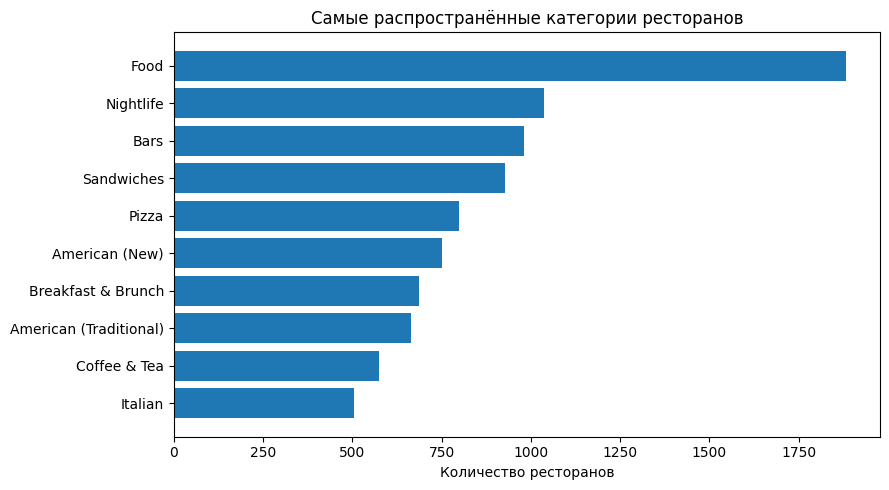

In [215]:
from collections import Counter

cat_counter = Counter()

for categories in meta_business["categories"].dropna():
    cat_counter.update(
        c.strip()
        for c in categories.split(",")
        if c.strip() and c.strip() != "Restaurants"
    )

top_categories = cat_counter.most_common(10)

labels, values = zip(*reversed(top_categories))

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(labels, values)

ax.set(
    title="Самые распространённые категории ресторанов",
    xlabel="Количество ресторанов"
)

plt.tight_layout()
plt.show()

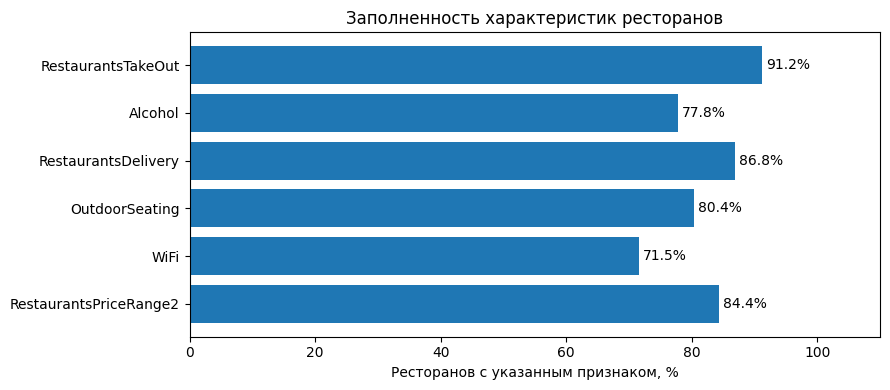

In [216]:
features = [
    "RestaurantsPriceRange2",
    "WiFi",
    "OutdoorSeating",
    "RestaurantsDelivery",
    "Alcohol",
    "RestaurantsTakeOut"
]

coverage = {}

for feature in features:
    coverage[feature] = meta_business["attributes"].apply(
        lambda x: (
            isinstance(x, dict)
            and x.get(feature) not in (None, "None", "", "Не указано")
        )
    ).mean() * 100

fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.barh(
    list(coverage.keys()),
    list(coverage.values())
)

ax.bar_label(bars, fmt="%.1f%%", padding=3)

ax.set(
    title="Заполненность характеристик ресторанов",
    xlabel="Ресторанов с указанным признаком, %"
)

ax.set_xlim(0, 110)

plt.tight_layout()
plt.show()

In [217]:
attributes_df = pd.DataFrame([
    a if isinstance(a, dict) else {}
    for a in meta_business["attributes"]
])

for feature in features:
    print(
        attributes_df[feature]
        .fillna("Не указано")
        .value_counts()
        .head(10)
    )

RestaurantsPriceRange2
2             2487
1             2165
Не указано     913
3              251
4               38
None             1
Name: count, dtype: int64
WiFi
Не указано    1665
u'no'         1639
u'free'       1615
'no'           504
'free'         396
u'paid'         23
'paid'          11
None             2
Name: count, dtype: int64
OutdoorSeating
False         2808
True          1899
Не указано     983
None           165
Name: count, dtype: int64
RestaurantsDelivery
True          3476
False         1607
Не указано     461
None           311
Name: count, dtype: int64
Alcohol
u'none'             2350
Не указано          1295
u'full_bar'         1073
'none'               593
'full_bar'           327
u'beer_and_wine'     168
'beer_and_wine'       46
None                   3
Name: count, dtype: int64
RestaurantsTakeOut
True          5054
Не указано     360
False          287
None           154
Name: count, dtype: int64


#### В некоторых признаках одинаковые значения записаны по-разному, например u'free' и 'free' для Wi-Fi. Перед обучением моделей приведём их к одному формату, а пропуски заменим на unknown.

In [218]:
def clean_attribute(value):
    if value is None:
        return "unknown"

    value = str(value).strip()

    if value in ("", "None", "null"):
        return "unknown"

    # Убираем старый префикс u и кавычки
    if value.startswith("u'") or value.startswith('u"'):
        value = value[1:]

    value = value.strip("'\"").lower()

    return value

for feature in features:
    attributes_df[feature] = (
        attributes_df[feature]
        .map(clean_attribute)
    )

    print(f"\n{feature}:")
    print(attributes_df[feature].value_counts())


RestaurantsPriceRange2:
RestaurantsPriceRange2
2          2487
1          2165
nan         913
3           251
4            38
unknown       1
Name: count, dtype: int64

WiFi:
WiFi
no         2143
free       2011
nan        1665
paid         34
unknown       2
Name: count, dtype: int64

OutdoorSeating:
OutdoorSeating
false      2808
true       1899
nan         983
unknown     165
Name: count, dtype: int64

RestaurantsDelivery:
RestaurantsDelivery
true       3476
false      1607
nan         461
unknown     311
Name: count, dtype: int64

Alcohol:
Alcohol
none             2943
full_bar         1400
nan              1295
beer_and_wine     214
unknown             3
Name: count, dtype: int64

RestaurantsTakeOut:
RestaurantsTakeOut
true       5054
nan         360
false       287
unknown     154
Name: count, dtype: int64


## 3. Подготовка данных и протокол оценки

Подготовим данные для обучения и сравнения моделей. Сначала очистим дубликаты отзывов и применим фильтрацию пользователей и ресторанов, затем разделим данные по времени на train, validation и test.

Для всех пяти моделей будем использовать одинаковое разбиение, наборы кандидатов и правила расчёта метрик.

In [219]:
data_raw = interactions.copy()

data_raw["date"] = pd.to_datetime(
    data_raw["date"], errors="coerce"
)

data_raw["stars"] = pd.to_numeric(
    data_raw["stars"], errors="coerce"
)

data_raw = data_raw.dropna(
    subset=["user_id", "business_id", "stars", "date"]
)

data_raw = data_raw[data_raw["stars"].between(1, 5)]

data_raw = data_raw.drop_duplicates(
    subset=["review_id"]
)

data_raw = data_raw.sort_values(
    ["date", "review_id"]
).reset_index(drop=True)

print("Отзывов после очистки:", len(data_raw))
print(
    "Повторных пар пользователь–ресторан:",
    data_raw.duplicated(["user_id", "business_id"]).sum()
)

Отзывов после очистки: 137034
Повторных пар пользователь–ресторан: 4349


### 3.1. Фильтрация пользователей и ресторанов

Проверим несколько вариантов фильтрации `(1, 1),`
   ` (2, 2),`
    `(3, 3),`
    `(5, 5),`
   ` (5, 3),`
    `(3, 2)` по минимальному количеству отзывов. Оставим вариант `(2, 2)`: не менее двух отзывов на пользователя и ресторан. Он позволяет сохранить достаточно данных для эксперимента.

In [220]:
def filter_interactions(df, min_user=1, min_item=1):
    result = df.copy()

    while True:
        old_size = len(result)

        user_counts = result["user_id"].value_counts()
        item_counts = result["business_id"].value_counts()

        result = result[
            result["user_id"].map(user_counts).ge(min_user)
            & result["business_id"].map(item_counts).ge(min_item)
        ].copy()

        if len(result) == old_size:
            break

    return result.reset_index(drop=True)


variants = [
    (1, 1),
    (2, 2),
    (3, 3),
    (5, 5),
    (5, 3),
    (3, 2)
]

results = []

for min_user, min_item in variants:
    filtered = filter_interactions(
        data_raw,
        min_user=min_user,
        min_item=min_item
    )

    results.append({
        "Мин. отзывов пользователя": min_user,
        "Мин. отзывов ресторана": min_item,
        "Пользователи": filtered["user_id"].nunique(),
        "Рестораны": filtered["business_id"].nunique(),
        "Взаимодействия": len(filtered)
    })

filter_stats = pd.DataFrame(results)

filter_stats["Подходит для ДЗ"] = (
    filter_stats["Взаимодействия"].between(100_000, 2_000_000)
    & filter_stats["Пользователи"].ge(1_000)
    & filter_stats["Рестораны"].ge(1_000)
)

display(filter_stats)

,Мин. отзывов пользователя,Мин. отзывов ресторана,Пользователи,Рестораны,Взаимодействия,Подходит для ДЗ
0,1,1,42316,5557,137034,True
1,2,2,16943,4772,111040,True
2,3,3,10090,4000,95964,False
3,5,5,5036,2913,75586,False
4,5,3,5239,3731,79168,False
5,3,2,10219,4619,97451,False


Окончательная выборка

In [221]:
data = filter_interactions(
    data_raw,
    min_user=2,
    min_item=2
)

data = data.sort_values(
    ["date", "review_id"]
).reset_index(drop=True)

n_users = data["user_id"].nunique()
n_items = data["business_id"].nunique()
n_reviews = len(data)

n_pairs = data[
    ["user_id", "business_id"]
].drop_duplicates().shape[0]


print("Отзывов:", n_reviews)
print("Уникальных пар:", n_pairs)
print("Пользователей:", n_users)
print("Ресторанов:", n_items)
print(f"Плотность коллаборативной матрицы: {n_pairs / (n_users * n_items):.4%}")


Отзывов: 111040
Уникальных пар: 106691
Пользователей: 16943
Ресторанов: 4772
Плотность коллаборативной матрицы: 0.1320%


### 3.2. Временное разбиение

Поскольку в данных есть даты отзывов, используем временное разбиение. Первые 80% взаимодействий отводим для train, следующие 10% — для validation и последние 10% - для test.

Гиперпараметры будем подбирать на validation. После выбора настроек обучим модели на train + validation и проведём итоговую оценку на test.

In [222]:
n = len(data)

train_end = int(n * 0.8)
val_end = int(n * 0.9)

train_events = data.iloc[:train_end].copy()
val_events = data.iloc[train_end:val_end].copy()
test_events = data.iloc[val_end:].copy()

split_stats = pd.DataFrame([
    {
        "Выборка": name,
        "Отзывов": len(df),
        "Начало": df["date"].min().date(),
        "Конец": df["date"].max().date()
    }
    for name, df in [
        ("Train", train_events),
        ("Validation", val_events),
        ("Test", test_events)
    ]
])

display(split_stats.style.hide(axis="index"))

Выборка,Отзывов,Начало,Конец
Train,88832,2005-08-22,2018-10-29
Validation,11104,2018-10-29,2019-12-03
Test,11104,2019-12-03,2022-01-19


### 3.3. Обработка повторных оценок

Пользователь мог несколько раз оценивать один ресторан. Для построения матрицы взаимодействий оставим последнюю оценку каждой пары пользователь-ресторан в пределах доступной обучающей истории.

Повторные оценки обрабатываем после временного разбиения, чтобы отзывы из validation и test не влияли на обучающие данные.

In [223]:
def latest_interactions(df):
    return (
        df.sort_values(["date", "review_id"])
          .drop_duplicates(
              ["user_id", "business_id"],
              keep="last"
          )
          .reset_index(drop=True)
    )

train = latest_interactions(train_events)

train_final_events = pd.concat(
    [train_events, val_events],
    ignore_index=True
)

train_final = latest_interactions(train_final_events)

print("Train:", len(train))
print("Train + Validation:", len(train_final))

Train: 85538
Train + Validation: 96154


### 3.4. Подготовка данных для оценки

В основной оценке используем только пользователей и рестораны, которые известны из обучающей выборки. Также исключаем повторные посещения уже известных пользователю ресторанов.

Новые пользователи и рестораны относятся к cold-start. Их количество оценим отдельно, но не будем включать в основное сравнение моделей.

In [224]:
def cold_start_stats(history, future):
    known_users = set(history["user_id"])
    known_items = set(history["business_id"])

    cold_users = ~future["user_id"].isin(known_users)
    cold_items = ~future["business_id"].isin(known_items)

    return {
        "Новых пользователей": future.loc[
            cold_users, "user_id"
        ].nunique(),

        "Новых ресторанов": future.loc[
            cold_items, "business_id"
        ].nunique(),

        "Отзывов с cold-start": (
            cold_users | cold_items
        ).sum()
    }


cold_stats = pd.DataFrame([
    {
        "Выборка": "Validation",
        **cold_start_stats(train, val_events)
    },
    {
        "Выборка": "Test",
        **cold_start_stats(train_final, test_events)
    }
])

display(cold_stats.style.hide(axis="index"))

Выборка,Новых пользователей,Новых ресторанов,Отзывов с cold-start
Validation,1495,292,5249
Test,1077,275,5003


Формируем данные для оценки

In [225]:
def prepare_evaluation(history, future):
    known_users = set(history["user_id"])
    known_items = set(history["business_id"])

    seen_pairs = pd.MultiIndex.from_frame(
        history[["user_id", "business_id"]]
    )

    future = future.copy()

    future_pairs = pd.MultiIndex.from_frame(
        future[["user_id", "business_id"]]
    )

    future = future[
        future["user_id"].isin(known_users)
        & future["business_id"].isin(known_items)
        & ~future_pairs.isin(seen_pairs)
    ].copy()
    future = (
        future.sort_values(["date", "review_id"])
              .drop_duplicates(
                  ["user_id", "business_id"],
                  keep="first"
              )
              .reset_index(drop=True)
    )

    return future


val_eval = prepare_evaluation(train, val_events)

test_eval = prepare_evaluation(
    train_final, test_events
)

In [226]:
eval_stats = []

for name, df in [
    ("Validation", val_eval),
    ("Test", test_eval)
]:
    positive = df[df["stars"] >= 4]

    eval_stats.append({
        "Выборка": name,
        "Взаимодействий": len(df),
        "Положительных": len(positive),
        "Пользователей для оценки": (
            positive["user_id"].nunique()
        )
    })

display(
    pd.DataFrame(eval_stats).style.hide(axis="index")
)

Выборка,Взаимодействий,Положительных,Пользователей для оценки
Validation,5495,3888,1630
Test,5651,4080,1698


### 3.5. Протокол оценки рекомендаций

Все пять моделей будем обучать и проверять на одних и тех же данных.

Сначала обучаем модели на `train` и подбираем параметры на `eval`. После этого переобучаем их на `train_final` (train + validation) и проверяем на `test_eval`.

Рекомендовать будем рестораны, которые есть в обучающих данных. При этом не будем предлагать пользователю заведения, о которых он уже оставлял отзывы.

Новых пользователей и рестораны пока не включаем в основную оценку, так как не все модели умеют с ними работать. Их количество посмотрели отдельно.

Хорошими рекомендациями считаем рестораны, которым пользователь поставил 4 или 5 звёзд. Качество будем оценивать по NDCG@10 и Recall@10. Основной метрикой для выбора лучших параметров будет NDCG@10.

In [227]:
def prepare_protocol(history, evaluation):
    all_items = set(history["business_id"])
    seen = history.groupby("user_id")["business_id"].agg(set).to_dict()
    positives = evaluation[evaluation["stars"] >= 4].groupby("user_id")["business_id"].agg(set).to_dict()
    candidates = {user: sorted(all_items - seen.get(user, set())) for user in positives}
    return positives, candidates

val_positives, val_candidates = prepare_protocol(train, val_eval)
test_positives, test_candidates = prepare_protocol(train_final, test_eval)

print("Validation users:", len(val_positives))
print("Test users:", len(test_positives))

Validation users: 1630
Test users: 1698


## Метрики
Оценивать модели будем по NDCG@10 и Recall@10.

In [228]:
def recall_at_k(recommended, relevant, k=10):
    return len(set(recommended[:k]) & relevant) / len(relevant) if relevant else 0.0

def ndcg_at_k(recommended, relevant, k=10):
    if not relevant: return 0.0
    dcg = sum(1 / np.log2(rank + 2) for rank, item in enumerate(recommended[:k]) if item in relevant)
    idcg = sum(1 / np.log2(rank + 2) for rank in range(min(k, len(relevant))))
    return dcg / idcg

def evaluate_model(recommend_fn, positives, candidates, k=10):
    rows=[]
    for user, relevant in positives.items():
        pred=list(recommend_fn(user, candidates[user], k))
        assert len(pred)==len(set(pred)) and len(pred)<=k
        assert set(pred).issubset(set(candidates[user]))
        rows.append({"NDCG@10":ndcg_at_k(pred,relevant,k),
                     "Recall@10":recall_at_k(pred,relevant,k)})
    per_user=pd.DataFrame(rows)
    return {"NDCG@10":per_user["NDCG@10"].mean(),
            "Recall@10":per_user["Recall@10"].mean(),"Users":len(per_user)}, per_user

## 4. Обучение моделей и подбор гиперпараметров

В этом разделе используем пять моделей, реализованных самостоятельно. На `train` обучаем варианты параметров и выбираем их по качеству на validation. **Метрики метрики: NDCG@10**, Recall@10. `test_eval` до окончательного выбора параметров не используем.

### 4.1 Выбор моделей

Для эксперимента были выбраны пять моделей, которые используют разные подходы к рекомендациям.

| Модель | Как работает | Какие данные использует |
|---|---|---|
| Item-based CF | Ищет похожие рестораны и рекомендует те, которые могут понравиться пользователю | Оценки пользователей |
| Explicit ALS | Находит скрытые предпочтения пользователей и особенности ресторанов | Оценки пользователей |
| EASE | Изучает связи между ресторанами на основе истории оценок | Оценки пользователей |
| FM | Учитывает не только пользователя и ресторан, но и их дополнительные характеристики | Оценки и метаданные |
| timeSVD++ | Учитывает предпочтения пользователя, его историю и изменения со временем | Оценки и даты отзывов |

Все модели, кроме FM, обучаем на оценках от 1 до 5 звёзд. Для FM используем бинарную цель: оценки 4–5 считаем положительными, а 1–3 — отрицательными.

В EASE сохраняем исходные оценки, а не заменяем каждый отзыв единицей.

После обучения каждая модель рассчитывает, насколько ресторан подходит пользователю. На основе этих значений составляем топ-10 рекомендаций и сравниваем модели по одинаковым метрикам.

In [229]:
from models.item_cf import ItemBasedCF
from models.als import ExplicitALS
from models.ease import EASE
from models.fm import FactorizationMachine
from models.time_svdpp import TimeSVDpp

### 4.3. Baseline

Выберем в качестве baseline random, он случайно выбирает 10 ресторанов из доступных пользователю. 


In [230]:
import numpy as np

class RandomBaseline:
    def __init__(self, seed=42):
        self.seed = seed

    def fit(self, df):
        return self

    def recommend(self, user_id, candidates, k=10):
        if not candidates:
            return []

        rng = np.random.default_rng(
            self.seed + sum(ord(c) for c in str(user_id))
        )

        n = min(k, len(candidates))

        return rng.choice(
            sorted(candidates),
            size=n,
            replace=False
        ).tolist()


random_model = RandomBaseline(seed=42).fit(train)

random_metrics, _ = evaluate_model(
    random_model.recommend,
    val_positives,
    val_candidates,
    k=10
)

print({
    key: round(float(value), 5)
    for key, value in random_metrics.items()
})

{'NDCG@10': 0.00121, 'Recall@10': 0.00244, 'Users': 1630.0}


### 4.4 Пространство поиска гиперпараметров

Для каждой модели проверяем небольшую заранее заданную сетку. Сетка ограничена по времени обучения; при необходимости её можно расширить **только на validation**. Основной критерий выбора — максимальный NDCG@10. В случае равенства оставляем первый вариант из сетки.

- **Item-based CF:** число соседей, минимальное число общих пользователей и shrinkage.
- **ALS:** число скрытых факторов, регуляризация и эпохи.
- **EASE:** коэффициент L2-регуляризации `reg`.
- **FM:** размер скрытого представления, скорость обучения и эпохи (при фиксированном batch size).
- **timeSVD++:** число факторов, скорость обучения и эпохи (при фиксированном batch size).

Ниже сетки явно сохранены в коде, чтобы подбор был воспроизводимым.

In [231]:
model_configs = {
    "Item-based CF": (
        lambda **p: ItemBasedCF(**p),
        {   "n_neighbors": [100, 500], "min_common": [2, 3], "shrinkage": [10.0, 20.0]},
    ),
    "Explicit ALS": (
        lambda **p: ExplicitALS(**p),
        {   "factors": [4, 8], "reg": [10.0, 15.0], "epochs": [10]},
    ),
    "EASE": (
        lambda **p: EASE(**p),
        {   "reg": [1000.0, 1100.0, 1200.0, 1300.0]},
    ),
    "FM": (
        lambda **p: FactorizationMachine(meta_business, meta_users, **p),
        {   "factors": [8, 16],
            "lr": [0.001, 0.003],
            "epochs": [10, 20],
            "batch_size": [1024]},
    ),
    "timeSVD++": (
        lambda **p: TimeSVDpp(**p),
        {   "factors": [8, 16],
            "lr": [0.001, 0.003],
            "epochs": [10, 20],
            "batch_size": [1024]}
    ),
}

for name, (_, grid) in model_configs.items():
    print(name, '—', grid)

Item-based CF — {'n_neighbors': [100, 500], 'min_common': [2, 3], 'shrinkage': [10.0, 20.0]}
Explicit ALS — {'factors': [4, 8], 'reg': [10.0, 15.0], 'epochs': [10]}
EASE — {'reg': [1000.0, 1100.0, 1200.0, 1300.0]}
FM — {'factors': [8, 16], 'lr': [0.001, 0.003], 'epochs': [10, 20], 'batch_size': [1024]}
timeSVD++ — {'factors': [8, 16], 'lr': [0.001, 0.003], 'epochs': [10, 20], 'batch_size': [1024]}


### 4.5 Подбор на validation

Обучаем каждую конфигурацию **только на `train`**. Для всех моделей используем одни и те же `val_positives` и `val_candidates`.

In [232]:
from itertools import product

def tune(name, maker, grid):
    rows = []
    best_score = -np.inf
    best_params = None
    keys = list(grid)
    for combo in product(*(grid[key] for key in keys)):
        params = dict(zip(keys, combo))
        model = maker(**params).fit(train)
        metrics, _ = evaluate_model(model.recommend, val_positives, val_candidates, k=10)
        rows.append({"model": name, **params, **metrics})
        print(name, params, 'NDCG@10 =', round(metrics['NDCG@10'], 5),
              'Recall@10 =', round(metrics['Recall@10'], 5))
        if metrics['NDCG@10'] > best_score:
            best_score = metrics['NDCG@10']
            best_params = params.copy()
    return pd.DataFrame(rows), best_params
all_search = []
best_settings = {}

for name, (maker, grid) in model_configs.items():
    search, params = tune(name, maker, grid)
    all_search.append(search)
    best_settings[name] = params

search_results = pd.concat(all_search, ignore_index=True)
display(search_results.sort_values('NDCG@10', ascending=False).head(15))

Item-based CF {'n_neighbors': 100, 'min_common': 2, 'shrinkage': 10.0} NDCG@10 = 0.00426 Recall@10 = 0.00833
Item-based CF {'n_neighbors': 100, 'min_common': 2, 'shrinkage': 20.0} NDCG@10 = 0.00438 Recall@10 = 0.00833
Item-based CF {'n_neighbors': 100, 'min_common': 3, 'shrinkage': 10.0} NDCG@10 = 0.0057 Recall@10 = 0.00904
Item-based CF {'n_neighbors': 100, 'min_common': 3, 'shrinkage': 20.0} NDCG@10 = 0.00581 Recall@10 = 0.00927
Item-based CF {'n_neighbors': 500, 'min_common': 2, 'shrinkage': 10.0} NDCG@10 = 0.00436 Recall@10 = 0.00829
Item-based CF {'n_neighbors': 500, 'min_common': 2, 'shrinkage': 20.0} NDCG@10 = 0.00432 Recall@10 = 0.00814
Item-based CF {'n_neighbors': 500, 'min_common': 3, 'shrinkage': 10.0} NDCG@10 = 0.00572 Recall@10 = 0.00833
Item-based CF {'n_neighbors': 500, 'min_common': 3, 'shrinkage': 20.0} NDCG@10 = 0.00589 Recall@10 = 0.00872
Explicit ALS {'factors': 4, 'reg': 10.0, 'epochs': 10} NDCG@10 = 0.01598 Recall@10 = 0.02563
Explicit ALS {'factors': 4, 'reg': 1

,model,n_neighbors,min_common,shrinkage,NDCG@10,Recall@10,Users,factors,reg,epochs,lr,batch_size
14,EASE,NaN,NaN,NaN,0.024738,0.039034,1630,NaN,1200.0,NaN,NaN,NaN
15,EASE,NaN,NaN,NaN,0.024714,0.039051,1630,NaN,1300.0,NaN,NaN,NaN
12,EASE,NaN,NaN,NaN,0.024552,0.038895,1630,NaN,1000.0,NaN,NaN,NaN
13,EASE,NaN,NaN,NaN,0.024410,0.038333,1630,NaN,1100.0,NaN,NaN,NaN
9,Explicit ALS,NaN,NaN,NaN,0.018752,0.029701,1630,4.0,15.0,10.0,NaN,NaN
11,Explicit ALS,NaN,NaN,NaN,0.017824,0.027611,1630,8.0,15.0,10.0,NaN,NaN
8,Explicit ALS,NaN,NaN,NaN,0.015977,0.025630,1630,4.0,10.0,10.0,NaN,NaN
10,Explicit ALS,NaN,NaN,NaN,0.015931,0.026479,1630,8.0,10.0,10.0,NaN,NaN
24,timeSVD++,NaN,NaN,NaN,0.010555,0.016362,1630,8.0,NaN,10.0,0.001,1024.0
28,timeSVD++,NaN,NaN,NaN,0.008010,0.010751,1630,16.0,NaN,10.0,0.001,1024.0


### 4.6. Фиксация лучших параметров

После завершения подбора сохраняем **все** испытанные конфигурации и лучшие параметры. Только после этого переходим к финальному сравнению в разделе 5.

In [233]:
from pathlib import Path

display(pd.DataFrame([
    {'Модель': name, 'Лучшие параметры': str(params)}
    for name, params in best_settings.items()
]))

,Модель,Лучшие параметры
0,Item-based CF,"{'n_neighbors': 500, 'min_common': 3, 'shrinka..."
1,Explicit ALS,"{'factors': 4, 'reg': 15.0, 'epochs': 10}"
2,EASE,{'reg': 1200.0}
3,FM,"{'factors': 8, 'lr': 0.001, 'epochs': 20, 'bat..."
4,timeSVD++,"{'factors': 8, 'lr': 0.001, 'epochs': 10, 'bat..."


## 5. Сравнение моделей при K = 10

Оцениваем модели по **NDCG@10** и **Recall@10**. NDCG учитывает позиции релевантных ресторанов в топ-10, а Recall долю известных положительных ресторанов, найденных в топ-10. Положительный отзыв - `stars >= 4`; остальные отзывы не считаем положительными целями. Для всех моделей используются одинаковые пользователи и наборы кандидатов.

Сначала показываем результаты validation, по которым выбирались параметры. Затем обучаем выбранные конфигурации на `train_final` (train + validation) и сравниваем на test.

### 5.1 Итог подбора на validation

In [234]:
best_rows = (
    search_results
    .sort_values("NDCG@10", ascending=False, kind="stable")
    .drop_duplicates("model")
)

validation_table = pd.concat([
    pd.DataFrame([{
        "model": "Random",
        "NDCG@10": random_metrics["NDCG@10"],
        "Recall@10": random_metrics["Recall@10"]
    }]),
    best_rows[["model", "NDCG@10", "Recall@10"]]
], ignore_index=True)

validation_table = (
    validation_table
    .sort_values("NDCG@10", ascending=False)
    .reset_index(drop=True)
)

display(
    validation_table.style.format({
        "NDCG@10": "{:.5f}",
        "Recall@10": "{:.5f}"
    }).hide(axis="index")
)

model,NDCG@10,Recall@10
EASE,0.02474,0.03903
Explicit ALS,0.01875,0.02970
timeSVD++,0.01055,0.01636
Item-based CF,0.00589,0.00872
FM,0.00552,0.00451
Random,0.00121,0.00244


### 5.2. Оцениваем на test

In [235]:
final_rows = []

for name, (maker, _) in model_configs.items():
    params = best_settings[name]

    model = maker(**params).fit(train_final)

    metrics, _ = evaluate_model(
        model.recommend,
        test_positives,
        test_candidates,
        k=10
    )

    final_rows.append({
        "Модель": name,
        "Параметры": str(params),
        "NDCG@10": float(metrics["NDCG@10"]),
        "Recall@10": float(metrics["Recall@10"])
    })

    print(
        f"{name}: "
        f"NDCG@10 = {metrics['NDCG@10']:.5f}, "
        f"Recall@10 = {metrics['Recall@10']:.5f}"
    )


baseline_final = RandomBaseline().fit(train_final)

base_test, _ = evaluate_model(
    baseline_final.recommend,
    test_positives,
    test_candidates,
    k=10
)

final_rows.append({
    "Модель": "Most Popular",
    "Параметры": "—",
    "NDCG@10": float(base_test["NDCG@10"]),
    "Recall@10": float(base_test["Recall@10"])
})


test_table = (
    pd.DataFrame(final_rows)
    .sort_values("NDCG@10", ascending=False)
    .reset_index(drop=True)
)

display(
    test_table.style
    .format({
        "NDCG@10": "{:.5f}",
        "Recall@10": "{:.5f}"
    })
    .hide(axis="index")
)


Item-based CF: NDCG@10 = 0.00537, Recall@10 = 0.00807
Explicit ALS: NDCG@10 = 0.02208, Recall@10 = 0.03399
EASE: NDCG@10 = 0.02616, Recall@10 = 0.04057
FM: NDCG@10 = 0.00136, Recall@10 = 0.00324
timeSVD++: NDCG@10 = 0.00370, Recall@10 = 0.00794


Модель,Параметры,NDCG@10,Recall@10
EASE,{'reg': 1200.0},0.02616,0.04057
Explicit ALS,"{'factors': 4, 'reg': 15.0, 'epochs': 10}",0.02208,0.03399
Item-based CF,"{'n_neighbors': 500, 'min_common': 3, 'shrinkage': 20.0}",0.00537,0.00807
timeSVD++,"{'factors': 8, 'lr': 0.001, 'epochs': 10, 'batch_size': 1024}",0.00370,0.00794
FM,"{'factors': 8, 'lr': 0.001, 'epochs': 20, 'batch_size': 1024}",0.00136,0.00324
Most Popular,—,0.00103,0.00223


## 6. Выводы 

Лучший результат на test показала **EASE** с параметром `reg=1200`: NDCG@10 = 0.02616 и Recall@10 = 0.04057. На втором месте оказалась Explicit ALS с NDCG@10 = 0.02208. Обе модели используют оценки пользователей, но по-разному находят связи между пользователями и ресторанами.

Item-based CF показала заметно более низкий результат (NDCG@10 = 0.00537). Возможно, это связано с тем, что у многих пользователей мало отзывов, поэтому модели сложно находить достаточно похожие рестораны.

FM, которая дополнительно учитывает категории, цены и другие характеристики ресторанов, получила NDCG@10 = 0.00136. То есть в нашем эксперименте она не смогла обойти модели, использующие только оценки. Но это ещё не значит, что метаданные бесполезны: чтобы проверить их влияние, нужно сравнить FM с метаданными и без них.

timeSVD++ тоже уступила EASE и ALS: NDCG@10 = 0.00370. Получается, что использование времени в нашей реализации не привело к улучшению качества. При этом нельзя говорить, что именно временные признаки ухудшили результат, так как модели отличаются и другими частями алгоритма.

Основное ограничение эксперимента — разреженность данных: у многих пользователей совсем небольшая история отзывов, как было видно на EDA. Кроме того, мы можем проверить рекомендации только по ресторанам, на которые пользователи действительно оставили отзывы. Если отзыва нет, это не обязательно означает, что ресторан человеку не понравился. 

Мы также рассматриваем только пользователей и рестораны, которые уже встречались в обучении, поэтому результаты не показывают, как модели работали бы с новыми пользователями или заведениями.

В итоге **EASE оказалась лучшей из пяти моделей в эксперименте**, а более сложные подходы с метаданными и временем не дали преимущества по выбранным метрикам.